# Researchly: topic modelling with LDA (Question 4)

Reads the cleaned corpus written by notebook 02, fits Latent Dirichlet Allocation with gensim, and builds the pyLDAvis intertopic map.

In [1]:
import os, re, base64, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel
import pyLDAvis, pyLDAvis.gensim_models
warnings.filterwarnings("ignore")

SEED = 42
FIG = "../outputs/figures/"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 4.1 LDA topics

In [2]:
corpus = pd.read_csv("../outputs/corpus_clean.csv")          # written by notebook 02
corpus["tokens"] = corpus["tokens"].str.split()
print(corpus[["doc_id", "topic_label", "n_tokens"]].to_string(index=False))

 doc_id            topic_label  n_tokens
      1          mixed methods      1204
      2 researcher reflexivity       953
      3 developmental research      1532
      4       Cronbach's alpha      2564
      5          triangulation      1620


In [3]:
# Five long articles are too few documents for LDA: every article would end up as a single topic mixture.
# Each article is therefore cut into consecutive passages of 50 tokens and every passage is one document.
WINDOW = 50
passages, owner = [], []
for _, r in corpus.iterrows():
    toks = r["tokens"]
    for start in range(0, len(toks) - WINDOW // 2, WINDOW):
        chunk = toks[start:start + WINDOW]
        if len(chunk) >= WINDOW // 2:
            passages.append(chunk); owner.append(r["doc_id"])
owner = np.array(owner)
print("passages:", len(passages), "| per article:", dict(zip(*np.unique(owner, return_counts=True))))

dictionary = corpora.Dictionary(passages)
dictionary.filter_extremes(no_below=3, no_above=0.5)           # rare words and words in over half the passages
bow = [dictionary.doc2bow(p) for p in passages]
print("vocabulary after filtering:", len(dictionary))

passages: 157 | per article: {np.int64(1): np.int64(24), np.int64(2): np.int64(19), np.int64(3): np.int64(31), np.int64(4): np.int64(51), np.int64(5): np.int64(32)}
vocabulary after filtering: 615


k =  2   c_v = 0.560


k =  3   c_v = 0.401


k =  4   c_v = 0.550


k =  5   c_v = 0.522


k =  6   c_v = 0.484


k =  7   c_v = 0.479


k =  8   c_v = 0.474


k =  9   c_v = 0.466


k = 10   c_v = 0.490


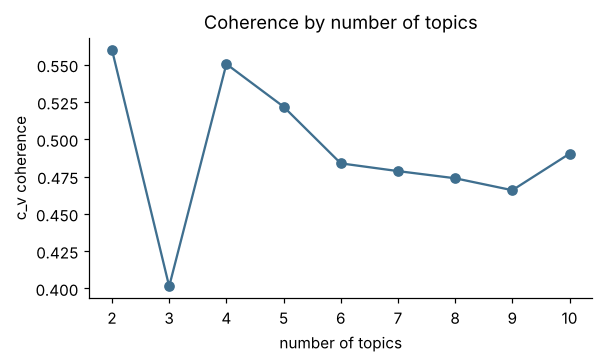

In [4]:
# Choose the number of topics with c_v coherence. A fixed seed and several passes keep the runs comparable.
ks = list(range(2, 11))
coh = []
for k in ks:
    m = LdaModel(bow, num_topics=k, id2word=dictionary, passes=20, iterations=200,
                 alpha="auto", eta="auto", random_state=SEED)
    cm = CoherenceModel(model=m, texts=passages, dictionary=dictionary, coherence="c_v", processes=1)
    coh.append(cm.get_coherence())
    print(f"k = {k:2d}   c_v = {coh[-1]:.3f}")

plt.figure(figsize=(5.5, 3.4))
plt.plot(ks, coh, "o-", color="#3f6f8f")
plt.xlabel("number of topics"); plt.ylabel("c_v coherence"); plt.title("Coherence by number of topics")
plt.tight_layout(); plt.savefig(FIG + "q4_coherence.png", dpi=150); plt.show()

Five documents are too few for LDA, so each article was cut into consecutive passages of 50 tokens, giving 157 passages and a 615-word vocabulary after removing words that occur in fewer than 3 passages or in more than half of them.

Coherence (c_v) is highest at 2 topics (0.560), falls to 0.401 at 3, and is 0.550 at 4 and 0.522 at 5. Two topics only separate the Cronbach's alpha article from everything else, which is too coarse to be useful, so 4 topics were chosen as the best value above that. Coherence values from different seeds move by a few hundredths, so the difference between 2 and 4 should not be over-read.

In [5]:
N_TOPICS = 4
lda = LdaModel(bow, num_topics=N_TOPICS, id2word=dictionary, passes=40, iterations=400,
               alpha="auto", eta="auto", random_state=SEED)
final_coh = CoherenceModel(model=lda, texts=passages, dictionary=dictionary, coherence="c_v", processes=1).get_coherence()
print("topics:", N_TOPICS, "| c_v coherence: %.3f" % final_coh)

topics: 4 | c_v coherence: 0.554


In [6]:
rows = []
for t in range(N_TOPICS):
    for w, p in lda.show_topic(t, topn=10):
        rows.append({"topic": t + 1, "word": w, "probability": round(float(p), 4)})
topic_words = pd.DataFrame(rows)
table = topic_words.groupby("topic").apply(lambda d: ", ".join(f"{w} ({p:.3f})" for w, p in zip(d.word, d.probability)))
for t, line in table.items():
    print(f"Topic {t}: {line}\n")
topic_words.to_csv("../outputs/lda_topic_words.csv", index=False)

Topic 1: alpha (0.053), instrument (0.031), cronbach (0.029), value (0.029), report (0.025), reliability (0.025), science (0.023), scale (0.022), item (0.020), measure (0.015)

Topic 2: researcher (0.029), reflexivity (0.025), knowledge (0.022), process (0.021), experience (0.021), product (0.014), address (0.013), orientation (0.012), personal (0.011), development (0.010)

Topic 3: development (0.058), design (0.036), developmental (0.029), process (0.028), instructional (0.026), field (0.016), term (0.013), type (0.012), learn (0.011), evaluation (0.010)

Topic 4: data (0.043), method (0.036), researcher (0.033), triangulation (0.030), qualitative (0.028), mixed (0.020), design (0.019), quantitative (0.014), multiple (0.014), denzin (0.011)



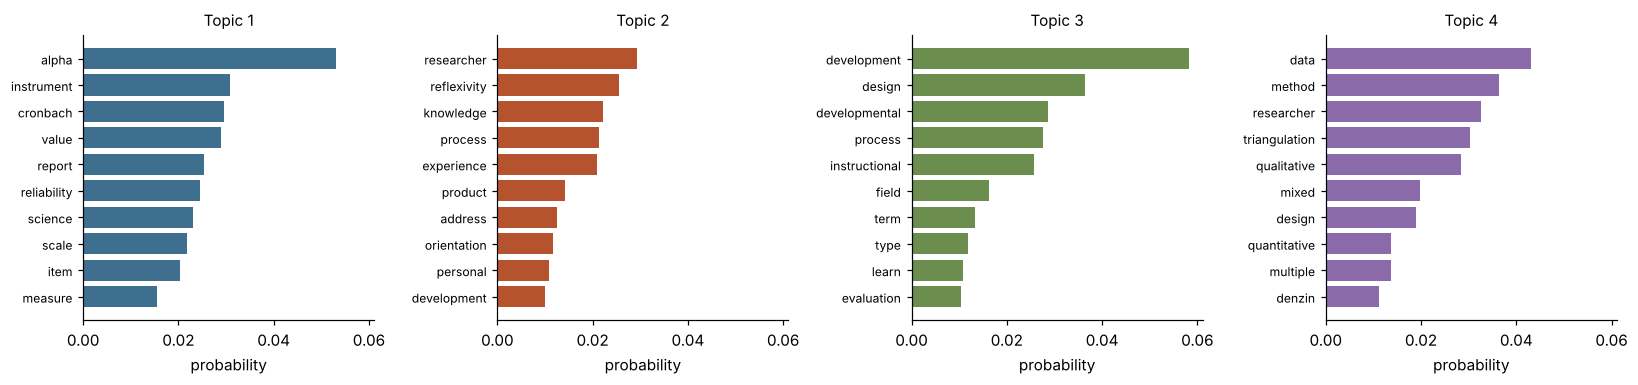

In [7]:
fig, axes = plt.subplots(1, N_TOPICS, figsize=(15, 3.6), sharex=True)
palette = ["#3f6f8f", "#b5532f", "#6b8e4e", "#8a6aa8", "#c09a3a"]
for t, ax in enumerate(axes):
    d = topic_words[topic_words.topic == t + 1].iloc[::-1]
    ax.barh(d.word, d.probability, color=palette[t])
    ax.set_title(f"Topic {t + 1}", fontsize=10); ax.tick_params(axis="y", labelsize=8)
    ax.set_xlabel("probability")
plt.tight_layout(); plt.savefig(FIG + "q4_topic_words.png", dpi=150); plt.show()

In [8]:
# Topic mixture of every passage, then averaged per article.
theta = np.zeros((len(bow), N_TOPICS))
for i, b in enumerate(bow):
    for t, p in lda.get_document_topics(b, minimum_probability=0):
        theta[i, t] = p
labels = dict(zip(corpus.doc_id, corpus.topic_label))
by_article = pd.DataFrame(theta).groupby(owner).mean()
by_article.index = [f"{i}: {labels[i]}" for i in by_article.index]
by_article.columns = [f"Topic {t + 1}" for t in range(N_TOPICS)]
print(by_article.round(2))
dominant = pd.crosstab(owner, theta.argmax(axis=1) + 1)
dominant.index = [f"{i}: {labels[i]}" for i in dominant.index]
print("\nPassages whose strongest topic is...:")
print(dominant)
share = theta.mean(axis=0)
print("\noverall topic share:", dict(zip(range(1, N_TOPICS + 1), share.round(3))))

                           Topic 1  Topic 2  Topic 3  Topic 4
1: mixed methods              0.02     0.01     0.03     0.94
2: researcher reflexivity     0.00     0.88     0.02     0.10
3: developmental research     0.00     0.35     0.63     0.02
4: Cronbach's alpha           0.91     0.01     0.08     0.00
5: triangulation              0.01     0.04     0.02     0.93

Passages whose strongest topic is...:
col_0                       1   2   3   4
1: mixed methods            0   0   1  23
2: researcher reflexivity   0  19   0   0
3: developmental research   0  12  19   0
4: Cronbach's alpha        51   0   0   0
5: triangulation            0   1   0  31

overall topic share: {1: np.float64(0.301), 2: np.float64(0.188), 3: np.float64(0.16), 4: np.float64(0.351)}


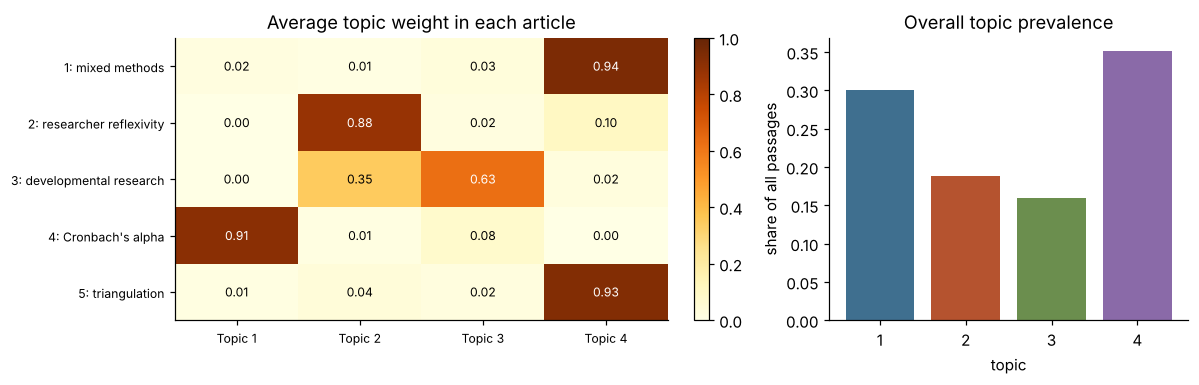

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
im = ax[0].imshow(by_article.values, cmap="YlOrBr", aspect="auto", vmin=0, vmax=1)
ax[0].set_xticks(range(N_TOPICS)); ax[0].set_xticklabels(by_article.columns, fontsize=8)
ax[0].set_yticks(range(len(by_article))); ax[0].set_yticklabels(by_article.index, fontsize=8)
for i in range(by_article.shape[0]):
    for j in range(N_TOPICS):
        ax[0].text(j, i, f"{by_article.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                   color="white" if by_article.values[i, j] > 0.55 else "black")
ax[0].set_title("Average topic weight in each article"); plt.colorbar(im, ax=ax[0], fraction=0.035)
ax[1].bar(range(1, N_TOPICS + 1), share, color=palette[:N_TOPICS])
ax[1].set_xticks(range(1, N_TOPICS + 1)); ax[1].set_xlabel("topic"); ax[1].set_ylabel("share of all passages")
ax[1].set_title("Overall topic prevalence")
plt.tight_layout(); plt.savefig(FIG + "q4_doc_topic.png", dpi=150); plt.show()

**Reading the topics.** Topic 1 is the Cronbach's alpha article (*alpha, instrument, cronbach, reliability, scale, item*). Topic 2 is researcher reflexivity (*researcher, reflexivity, knowledge, experience, personal*). Topic 3 is instructional design and developmental research (*development, design, developmental, instructional, evaluation*). Topic 4 covers mixed methods and triangulation (*data, method, triangulation, qualitative, mixed, quantitative, denzin*).

**Documents.** Articles 1 and 5 both load on Topic 4 (0.94 and 0.93), which fits, as both are about combining qualitative and quantitative methods. Article 4 loads 0.91 on Topic 1 and article 2 loads 0.88 on Topic 2. Article 3 is split, 0.63 on Topic 3 and 0.35 on Topic 2, because its passages on researchers and knowledge production overlap with the reflexivity vocabulary. Topic 4 holds the largest share of all passages (35%), followed by Topic 1 (30%), Topic 2 (19%) and Topic 3 (16%).

## 4.2 Intertopic distance map (pyLDAvis)

In [10]:
vis = pyLDAvis.gensim_models.prepare(lda, bow, dictionary, sort_topics=False, mds="mmds")
pyLDAvis.enable_notebook()
pyLDAvis.display(vis)

In [11]:
# Write a self-contained copy of the interactive map. The d3 and LDAvis scripts that ship with pyLDAvis are
# embedded in the file, so it opens by double-click without internet access.
pkg = os.path.dirname(pyLDAvis.__file__)
def data_uri(path, mime):
    with open(os.path.join(pkg, "js", path), "rb") as fh:
        return f"data:{mime};base64," + base64.b64encode(fh.read()).decode()

html = pyLDAvis.prepared_data_to_html(vis)
html = html.replace("https://d3js.org/d3.v5.js", data_uri("d3.v5.min.js", "text/javascript"))
html = html.replace("https://cdn.jsdelivr.net/gh/bmabey/pyLDAvis@3.4.0/pyLDAvis/js/ldavis.v3.0.0.js",
                    data_uri("ldavis.v3.0.0.js", "text/javascript"))
html = html.replace("https://cdn.jsdelivr.net/gh/bmabey/pyLDAvis@3.4.0/pyLDAvis/js/ldavis.v1.0.0.css",
                    data_uri("ldavis.v1.0.0.css", "text/css"))
with open("../outputs/lda_intertopic_map.html", "w", encoding="utf-8") as fh:
    fh.write(html)
print("saved ../outputs/lda_intertopic_map.html (%.0f KB)" % (os.path.getsize("../outputs/lda_intertopic_map.html") / 1024))
print("remaining external links:", re.findall(r"https?://[^\"' ]+", html)[:5])

saved ../outputs/lda_intertopic_map.html (494 KB)
remaining external links: ['https://d3js.org/d3.v5']


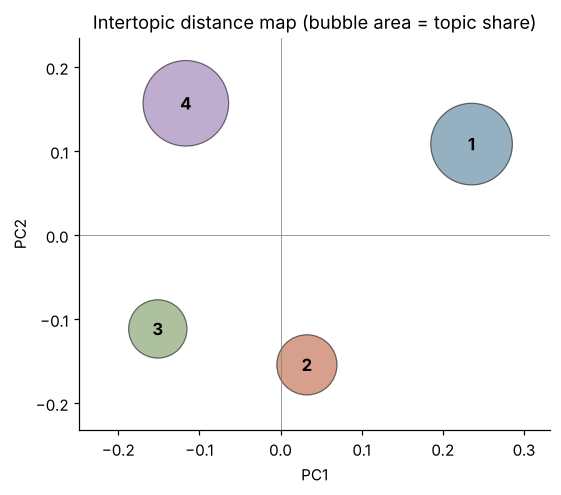

 topics     x     y  Freq
      1  0.24  0.11 31.73
      2  0.03 -0.15 17.24
      3 -0.15 -0.11 16.20
      4 -0.12  0.16 34.83


In [12]:
# The same intertopic coordinates, drawn with matplotlib so the map can sit in the written report.
coords = vis.topic_coordinates
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.scatter(coords["x"], coords["y"], s=coords["Freq"] * 90, c=palette[:N_TOPICS], alpha=0.55, edgecolor="black", linewidth=0.8)
for _, r in coords.iterrows():
    ax.annotate(int(r["topics"]), (r["x"], r["y"]), ha="center", va="center", fontsize=11, fontweight="bold")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Intertopic distance map (bubble area = topic share)")
ax.margins(0.25)
plt.tight_layout(); plt.savefig(FIG + "q4_intertopic_static.png", dpi=150); plt.show()
print(coords[["topics", "x", "y", "Freq"]].round(2).to_string(index=False))

In [13]:
# Terms the map's right-hand panel would rank first for each topic. Relevance (Sievert and Shirley, 2014)
# blends a term's probability inside the topic with how much more common it is there than in the corpus;
# lambda = 0.6 is the setting the authors found works well. Dragging the lambda slider in the map changes this.
tw = lda.get_topics()
term_freq = np.zeros(len(dictionary))
for b in bow:
    for i, c in b:
        term_freq[i] += c
p_w = term_freq / term_freq.sum()
lam = 0.6
for t in range(N_TOPICS):
    rel = lam * np.log(tw[t]) + (1 - lam) * np.log(tw[t] / p_w)
    top = np.argsort(rel)[::-1][:10]
    print(f"Topic {t + 1}:", ", ".join(dictionary[i] for i in top))

# Corpus-wide most salient terms (the default view of the map's left panel).
default = vis.topic_info[vis.topic_info.Category == "Default"].head(12)
print("\nMost salient terms overall:", ", ".join(f"{t} ({int(f)})" for t, f in zip(default.Term, default.Freq)))

Topic 1: alpha, instrument, cronbach, value, reliability, report, scale, item, science, measure
Topic 2: reflexivity, experience, product, researcher, knowledge, process, orientation, address, personal, share
Topic 3: development, developmental, instructional, design, process, field, nature, technology, term, solution
Topic 4: data, method, triangulation, qualitative, researcher, mixed, quantitative, multiple, design, denzin

Most salient terms overall: alpha (103), development (71), data (97), triangulation (65), cronbach (57), method (83), researcher (102), instrument (63), design (82), process (57), developmental (32), reflexivity (27)


The map is shown above and saved as `outputs/lda_intertopic_map.html`, which opens offline. Topics 4 and 1 are the largest bubbles and sit in the upper half. Topics 2 and 3 are smaller and sit in the lower half. The four bubbles do not overlap, so the topics are well separated. Selecting a topic shows its most relevant terms against their overall frequency, and the slider changes the relevance weight lambda. The most salient terms across the whole corpus are *alpha*, *development*, *data*, *triangulation*, *cronbach*, *method* and *researcher*.

The map uses metric MDS to place the topics (`mds="mmds"`). The default PCoA option failed with a complex-number error in this environment.